# MSI5001 — L4 Vectorization & Normalization | Reproducible Demo

**M1 TF-IDF · M2 engineered-feature scaling · M3 block weighting · M4 optional FastText**  
**Label-blind preparation only:** no K-means, sentiment labels, or external evaluation.

**Safety contract:** `EDA/0.Processed-files/` is **strictly read-only**. The notebook only reads P0/P1/P2 and the L3 master from that directory. **Exports are OFF by default**. When explicitly enabled, outputs go into a new, separate timestamped folder outside `0.Processed-files/`; existing files are never overwritten. The notebook itself is not uploaded to GitHub.

Run cells in order. On Colab use Google Drive; on a local machine, change `BASE` to your mounted EDA folder. The GitHub repository is used **only to import the already-merged L4 modules**.

## 0 — Settings and safeguards

In [1]:
from pathlib import Path
import os, sys, hashlib, json, time, subprocess, platform
import numpy as np
import pandas as pd

# EDIT BASE only if your EDA directory differs.
BASE = Path('/content/drive/MyDrive/MSI5001 project/EDA')
SOURCE_DIR = BASE / '0.Processed-files'  # NEVER WRITE HERE
WORK_PARENT = BASE / 'L4-Vec_norm' / 'L4 Demo outputs'

# Safe defaults. Turn on only after reviewing validation outputs.
EXPORT_ENABLED = False
RUN_FASTTEXT = True   # Set False for a faster M1–M3 demonstration
RUN_TESTS = False     # Optional full repository regression suite

REPO_URL = 'https://github.com/frankie-chew-nus/sentiment-clustering-ml.git'
REPO_DIR = Path('/content/sentiment-clustering-ml')

EXPECTED_HASHES = {
    'P0': 'd349148dce04344180bf7969f12b6ccd2180e387927738cd911da07dc30c00a4',
    'P1': 'fdeab9faa57b7ffb7ac33335aebafc5f153849d94647e0118d02e809a86c632e',
    'P2': '70600d91b2f1327e36b1dc20d3f079328623b9ccb4546a74228046051b989755',
    'MASTER': 'abb285f95c28a59bb35cbb797faabdcaac894f1c7d04885b4e7789dd3d88067c',
}
print('Exports enabled:', EXPORT_ENABLED)
print('Read-only source:', SOURCE_DIR)
print('Separate output parent:', WORK_PARENT)

Exports enabled: False
Read-only source: /content/drive/MyDrive/MSI5001 project/EDA/0.Processed-files
Separate output parent: /content/drive/MyDrive/MSI5001 project/EDA/L4-Vec_norm/L4 Demo outputs


## 1 — Mount Drive (Colab) and load the merged implementation

In [2]:
try:
    import google.colab
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Local Python: skipping Colab Drive mount. Set BASE above to your EDA directory.')

assert SOURCE_DIR.is_dir(), f'Missing source folder: {SOURCE_DIR}'
assert SOURCE_DIR.resolve() != WORK_PARENT.resolve()

# Git operations only in the runtime checkout, never in the read-only source folder.
if not (REPO_DIR / '.git').exists():
    subprocess.run(['git', 'clone', '--branch', 'main', REPO_URL, str(REPO_DIR)], check=True)
else:
    print('Using existing checkout:', REPO_DIR)
    print('For the latest merged main, update this checkout separately if needed.')

# Install project dependencies into current runtime, not into Drive.
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                str(REPO_DIR / 'requirements-dev.txt')], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gensim>=4.3.3'], check=True)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from vectorization import build_representation, save_representation
from feature_scaling import EngineeredFeatureScaler
from feature_scaling_config import ScalingSpec
from feature_integration import BlockIntegrator, WeightingSpec, save_integrated
from fasttext_representation import FastTextSpec, FastTextTweetEncoder, save_fasttext
from scipy import sparse

git_revision = subprocess.check_output(['git', '-C', str(REPO_DIR), 'rev-parse', 'HEAD'], text=True).strip()
print('Git revision:', git_revision)
print('Python:', platform.python_version())
if RUN_TESTS:
    subprocess.run([sys.executable, '-m', 'pytest', str(REPO_DIR / 'tests'), '-q'], cwd=REPO_DIR, check=True)

Mounted at /content/drive
Git revision: 1e2d6a3b67fb0dd40870e31f3eb1a7a1c768fdac
Python: 3.13.16


## 2 — Verify the validated L2/L3 inputs (read-only)

In [3]:
source_paths = {
    'P0': SOURCE_DIR / 'Tweets-processed-p0.csv',
    'P1': SOURCE_DIR / 'Tweets-processed-p1.csv',
    'P2': SOURCE_DIR / 'Tweets-processed-p2.csv',
    'MASTER': SOURCE_DIR / 'Tweets-L3-master-features.csv',
}
source_hashes = {}
for key, path in source_paths.items():
    assert path.is_file(), f'Missing source: {path}'
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == EXPECTED_HASHES[key], f'{key}: fingerprint mismatch; STOP before processing'
    source_hashes[key] = sha
    print(f'{key}: SHA256 PASS — {sha}')

texts_df = {key: pd.read_csv(source_paths[key], keep_default_na=False)
            for key in ('P0', 'P1', 'P2')}
master = pd.read_csv(source_paths['MASTER'])
for key, frame in texts_df.items():
    assert frame.shape == (14639, 2) and list(frame.columns) == ['text', 'processed_text']
    assert frame['processed_text'].map(lambda x: isinstance(x, str)).all()
    assert not frame['processed_text'].str.strip().eq('').any()
assert texts_df['P0']['text'].equals(texts_df['P1']['text'])
assert texts_df['P1']['text'].equals(texts_df['P2']['text'])
assert master.shape == (14639, 11)
assert np.array_equal(master['row_id'].to_numpy(), np.arange(14639))
print('Source hashes, original-tweet alignment and master row IDs: PASS')
print('Caveat: L3-to-text row mapping relies on validated upstream generation; master has no raw text column.')
text_by_variant = {key: frame['processed_text'].tolist() for key, frame in texts_df.items()}

P0: SHA256 PASS — d349148dce04344180bf7969f12b6ccd2180e387927738cd911da07dc30c00a4
P1: SHA256 PASS — fdeab9faa57b7ffb7ac33335aebafc5f153849d94647e0118d02e809a86c632e
P2: SHA256 PASS — 70600d91b2f1327e36b1dc20d3f079328623b9ccb4546a74228046051b989755
MASTER: SHA256 PASS — abb285f95c28a59bb35cbb797faabdcaac894f1c7d04885b4e7789dd3d88067c
Source hashes, original-tweet alignment and master row IDs: PASS
Caveat: L3-to-text row mapping relies on validated upstream generation; master has no raw text column.


## 3 — M1: Generate sparse TF-IDF matrices

In [4]:
m1_names = ['word_p1', 'word_p2', 'char_p0', 'char_p1', 'char_wb_p0',
            'combined_p1_p1', 'combined_p1_p0']
m1_matrices, m1_metadata, m1_rows = {}, {}, []
for name in m1_names:
    X_m1, fitted, metadata = build_representation(text_by_variant, name)
    assert sparse.isspmatrix_csr(X_m1) and X_m1.shape[0] == 14639
    assert np.isfinite(X_m1.data).all()
    row_norms = np.sqrt(np.asarray(X_m1.multiply(X_m1).sum(axis=1)).ravel())
    m1_matrices[name] = X_m1
    m1_metadata[name] = metadata
    m1_rows.append(dict(representation=name, rows=X_m1.shape[0], dimensions=X_m1.shape[1],
                        nnz=X_m1.nnz, density_pct=100*X_m1.nnz/(X_m1.shape[0]*X_m1.shape[1]),
                        zero_rows=int((row_norms == 0).sum()), mean_norm=float(row_norms.mean())))
m1_summary = pd.DataFrame(m1_rows)
display(m1_summary.round(5))
# Audit reference, not a requirement for other library versions.
print('Previously audited: word_p1=29792 dims; char_p0=50000; combined_p1_p0=79792.')

,representation,rows,dimensions,nnz,density_pct,zero_rows,mean_norm
0,word_p1,14639,29792,371747,0.08524,16,0.99891
1,word_p2,14639,17267,173532,0.06865,71,0.99515
2,char_p0,14639,50000,3332264,0.45526,0,1.00000
3,char_p1,14639,50000,3455072,0.47204,0,1.00000
4,char_wb_p0,14639,50000,2252967,0.30780,1,0.99993
5,combined_p1_p1,14639,79792,3826819,0.32762,0,1.41376
6,combined_p1_p0,14639,79792,3704011,0.31710,0,1.41376


Previously audited: word_p1=29792 dims; char_p0=50000; combined_p1_p0=79792.


## 4 — M2: Scaling and distribution diagnostics

In [5]:
scaling_variants = ('V1', 'N1', 'S3')
scaling_results, scaling_manifests, scale_rows = {}, {}, []
for method in ('bounded', 'log_only', 'standard'):
    scaler = EngineeredFeatureScaler(scaling_variants, ScalingSpec(method=method, percentile=95))
    X_scale = scaler.fit_transform(master)
    assert np.isfinite(X_scale).all()
    scaling_results[method] = X_scale
    scaling_manifests[method] = scaler.manifest()
    for j, column in enumerate(scaler.columns):
        a = X_scale[:, j]
        scale_rows.append(dict(method=method, feature=column, mean=a.mean(), std=a.std(),
                               p95=np.percentile(a, 95), maximum=a.max(), zero_pct=100*np.mean(a==0)))
scale_summary = pd.DataFrame(scale_rows)
display(scale_summary.round(4))
print('Bounded fitted references:', scaling_manifests['bounded']['references'])
print('Note: M3 baseline below uses V1+N1+S2, excluding S_emoji_count.')

,method,feature,mean,std,p95,maximum,zero_pct
0,bounded,V_compound,0.1352,0.4738,0.8313,0.9778,15.8686
1,bounded,N_negation_count,0.2352,0.3412,1.0000,1.0000,66.4185
2,bounded,S_exclamation_count,0.1668,0.3244,1.0000,1.0000,77.9630
3,bounded,S_uppercase_ratio,0.0288,0.0770,0.1429,0.9565,73.2427
4,bounded,S_emoji_count,0.0176,0.1013,0.0000,1.0000,96.6391
5,log_only,V_compound,0.1352,0.4738,0.8313,0.9778,15.8686
6,log_only,N_negation_count,0.2607,0.3809,1.0986,1.6094,66.4185
7,log_only,S_exclamation_count,0.1989,0.4064,1.0986,3.3322,77.9630
8,log_only,S_uppercase_ratio,0.0288,0.0770,0.1429,0.9565,73.2427
9,log_only,S_emoji_count,0.0324,0.1912,0.0000,3.7136,96.6391


Bounded fitted references: {'N_negation_count': {'reference': 1.0986122886681096}, 'S_exclamation_count': {'reference': 1.0986122886681096}, 'S_emoji_count': {'reference': 1.791759469228055}}
Note: M3 baseline below uses V1+N1+S2, excluding S_emoji_count.


## 5 — M3: Rebuild W0/W1/W2 from the five approved blocks

In [6]:
m3_scaler = EngineeredFeatureScaler(('V1', 'N1', 'S2'), ScalingSpec(method='bounded', percentile=95))
X_eng = m3_scaler.fit_transform(master)
blocks = {
    'word': m1_matrices['word_p1'],
    'char': m1_matrices['char_p0'],
    'V': X_eng[:, 0:1],
    'N': X_eng[:, 1:2],
    'S': X_eng[:, 2:4],
}
integrators, combined_matrices, weight_rows = {}, {}, []
for method in ('W0', 'W1', 'W2'):
    integrator = BlockIntegrator(WeightingSpec(method=method))
    X_combined = integrator.fit_transform(blocks)
    assert sparse.isspmatrix_csr(X_combined) and np.isfinite(X_combined.data).all()
    integrators[method], combined_matrices[method] = integrator, X_combined
    weighted = {name: integrator.distances_[name] * integrator.weights_[name]**2
                for name in integrator.names_}
    total = sum(weighted.values())
    for name in integrator.names_:
        weight_rows.append(dict(method=method, block=name,
                                original_mean_sq_distance=integrator.distances_[name],
                                coefficient=integrator.weights_[name],
                                contribution_pct=100*weighted[name]/total))
    print(method, 'shape', X_combined.shape, 'nnz', X_combined.nnz)
weight_summary = pd.DataFrame(weight_rows)
display(weight_summary.round(6))
for method, target in [('W1', {'word':20,'char':20,'V':20,'N':20,'S':20}),
                       ('W2', {'word':35,'char':35,'V':10,'N':10,'S':10})]:
    for block, pct in target.items():
        actual = weight_summary.query('method == @method and block == @block')['contribution_pct'].iloc[0]
        assert np.isclose(actual, pct, atol=1e-8)
print('W1 and W2 target calibration: PASS')

W0 shape (14639, 79796) nnz 3728386
W1 shape (14639, 79796) nnz 3728386
W2 shape (14639, 79796) nnz 3728386


,method,block,original_mean_sq_distance,coefficient,contribution_pct
0,W0,word,1.974836,1.000000,40.826494
1,W0,char,1.958069,1.000000,40.479868
2,W0,V,0.449029,1.000000,9.282941
3,W0,N,0.232866,1.000000,4.814117
4,W0,S,0.222343,1.000000,4.596580
5,W1,word,1.974836,0.318236,20.000000
6,W1,char,1.958069,0.319596,20.000000
7,W1,V,0.449029,0.667387,20.000000
8,W1,N,0.232866,0.926749,20.000000
9,W1,S,0.222343,0.948425,20.000000


W1 and W2 target calibration: PASS


## 6 — M4: Optional corpus-trained FastText on P1

In [7]:
fasttext_encoder = None
fasttext_X = None
fasttext_zero_rows = None
fasttext_summary = {}
if RUN_FASTTEXT:
    spec = FastTextSpec(vector_size=100, window=5, min_count=2, epochs=10,
                        sg=1, seed=5001, workers=1)
    fasttext_encoder = FastTextTweetEncoder(spec)
    t0 = time.perf_counter()
    fasttext_X, fasttext_zero_rows = fasttext_encoder.fit_transform(text_by_variant['P1'])
    elapsed = time.perf_counter() - t0
    norms = np.linalg.norm(fasttext_X, axis=1)
    assert fasttext_X.shape == (14639, 100) and np.isfinite(fasttext_X).all()
    assert np.allclose(norms[norms > 0], 1, atol=1e-10)
    from collections import Counter
    counts = Counter(t for line in text_by_variant['P1'] for t in line.split())
    explicit = set(fasttext_encoder.model_.wv.key_to_index)
    covered = sum(count for token, count in counts.items() if token in explicit)
    fasttext_summary = dict(seconds=elapsed, rows=len(fasttext_X), dimensions=100,
        zero_vectors=len(fasttext_zero_rows), explicit_vocab=len(explicit),
        tfidf_vocab=len(fasttext_encoder.idf_), unique_tokens=len(counts),
        token_occurrences=sum(counts.values()), explicit_coverage_pct=100*covered/sum(counts.values()),
        min_norm=float(norms.min()), mean_norm=float(norms.mean()), max_norm=float(norms.max()))
    display(pd.DataFrame([fasttext_summary]).round(4))
    for a,b in [('excellent','terrible'),('good','bad'),('great','awful'),('happy','angry')]:
        try:
            print(f'{a} / {b}: {fasttext_encoder.model_.wv.similarity(a,b):.4f}')
        except KeyError:
            print(a,b,'unavailable')
else:
    print('FastText skipped; set RUN_FASTTEXT=True in section 0 and rerun in order.')

,seconds,rows,dimensions,zero_vectors,explicit_vocab,tfidf_vocab,unique_tokens,token_occurrences,explicit_coverage_pct,min_norm,mean_norm,max_norm
0,28.7942,14639,100,0,8814,24135,24135,262713,94.1682,1.0,1.0,1.0


excellent / terrible: 0.8139
good / bad: 0.6190
great / awful: 0.6617
happy / angry: 0.6430


## 7 — Read-only numerical visualizations

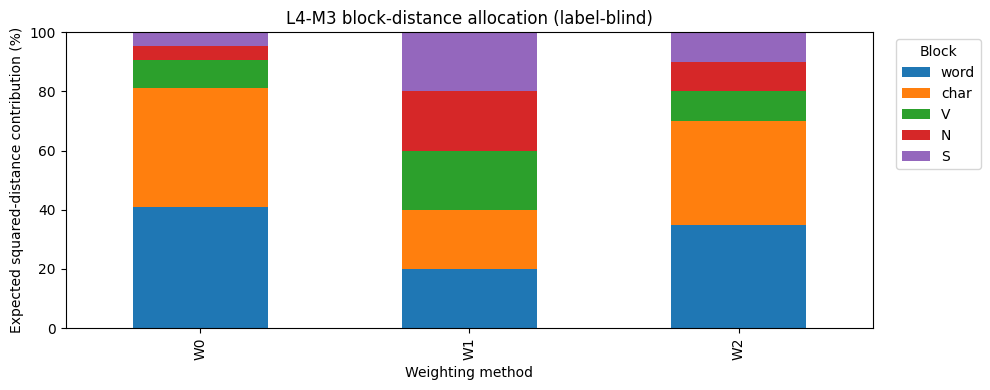

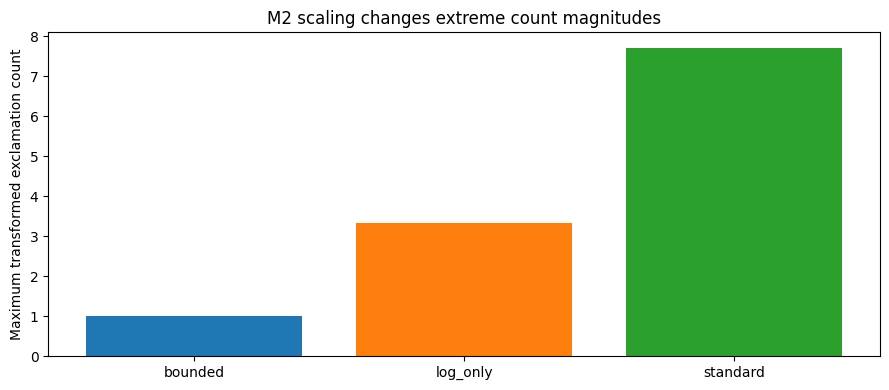

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4))
contrib = weight_summary.pivot(index='method', columns='block', values='contribution_pct')
contrib = contrib[['word','char','V','N','S']]
contrib.plot(kind='bar', stacked=True, ax=ax)
ax.set_ylabel('Expected squared-distance contribution (%)')
ax.set_xlabel('Weighting method')
ax.set_ylim(0, 100)
ax.set_title('L4-M3 block-distance allocation (label-blind)')
ax.legend(title='Block', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for method in ('bounded', 'log_only', 'standard'):
    row = scale_summary.query('method == @method and feature == "S_exclamation_count"').iloc[0]
    ax.bar(method, row['maximum'])
ax.set_ylabel('Maximum transformed exclamation count')
ax.set_title('M2 scaling changes extreme count magnitudes')
plt.tight_layout()
plt.show()

## 8 — Optional export (disabled by default)

**Safety:** The following cell does nothing unless you set `EXPORT_ENABLED = True` in section 0. When enabled, it creates a **new unique timestamped folder** inside `EDA/L4-Vec_norm/L4 Demo outputs/` and never writes to `EDA/0.Processed-files/`. Output filenames are prefixed `L4-` for convenience. SHA256 hashes of regenerated files may differ from the original exports, especially FastText, because library versions, training, and NPZ serialization can vary.

The generated `.json` manifests are accompanied by a `demo_provenance.json` mapping input fingerprints, the code revision, and regenerated outputs. These are demonstration artifacts, **not automatic replacements for the validated master files**.

In [ ]:
from datetime import datetime, timezone
if not EXPORT_ENABLED:
    print('SAFE MODE: exports disabled; no new output files created.')
else:
    # A fixed guard ensures that output paths cannot resolve inside read-only master folder.
    assert SOURCE_DIR.resolve() not in WORK_PARENT.resolve().parents
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    out_dir = WORK_PARENT / f'demo_{run_id}'
    out_dir.mkdir(parents=True, exist_ok=False)
    provenance = {'git_revision': git_revision, 'sources': source_hashes}
    generated = []
    for name in m1_names:
        prefix = out_dir / ('L4-' + name)
        mpath, jpath = save_representation(m1_matrices[name], m1_metadata[name], prefix)
        generated.extend([mpath, jpath])
    for method in ('W0', 'W1', 'W2'):
        prefix = out_dir / ('L4-' + method)
        mpath, jpath = save_integrated(combined_matrices[method], integrators[method].manifest(),
                                      prefix, provenance)
        generated.extend([mpath, jpath])
    if RUN_FASTTEXT and fasttext_X is not None:
        prefix = out_dir / 'L4-fasttext_p1_100d'
        mpath, jpath = save_fasttext(fasttext_X, fasttext_zero_rows,
                                     fasttext_encoder.manifest(), prefix,
                                     {'git_revision': git_revision, 'p1_sha256': source_hashes['P1']})
        generated.extend([mpath, jpath])
    # M2 scaling reference metadata; the L3 master remains untouched.
    m2_path = out_dir / 'L4-M2-scaling-audit.json'
    m2_path.write_text(json.dumps({'methods': scaling_manifests,
                                   'M3_baseline': m3_scaler.manifest()}, indent=2), encoding='utf-8')
    generated.append(str(m2_path))
    audit_path = out_dir / 'demo_provenance.json'
    audit_path.write_text(json.dumps({'git_revision': git_revision,
        'source_sha256': source_hashes, 'generated_files': [Path(p).name for p in generated],
        'm1_summary': m1_summary.to_dict(orient='records'),
        'm3_weights': weight_summary.to_dict(orient='records'),
        'fasttext_summary': fasttext_summary}, indent=2), encoding='utf-8')
    generated.append(str(audit_path))
    for path in generated:
        assert Path(path).is_file()
    print('Export complete:', out_dir)
    print('Files:', len(generated))

## 9 — L4 → L5 handover notes

- **Primary label-blind inputs:** P1 word TF-IDF, P0 character TF-IDF, combined P1+P0, W0/W1/W2, optional corpus-trained FastText. Their corresponding JSON manifests describe configuration and provenance.
- **Data policy:** `EDA/0.Processed-files/` remains strictly read-only. L5 must read the `L4-`-prefixed validated files there, but write all new clustering outputs elsewhere.
- **Interpretation:** W1/W2 percentages are calibrated distance contributions, **not proven sentiment-optimal weights**. The FastText polarity-opposition similarities are diagnostics, not external evaluation.
- **Research boundary:** Do not use sentiment labels or confidence columns for feature selection, weighting, K-means, or tuning. Reserve labels for L6 external evaluation.
- **Reproducibility:** The notebook reads source CSVs only, uses merged project modules, and never automatically pushes files to GitHub. When you are satisfied, upload the notebook manually if desired.
